# 05 — Multimodal evidence feasibility and architecture

Documents the image branch, evaluates its held-out damage-class performance, and defines a conservative fusion rule. The branch does not estimate fraud because no downloaded image dataset has verified claim-level fraud labels linked to the tabular benchmark.

**Reproducibility rule:** outputs below are generated from the untouched held-out test set or from validation/CV reports; no test result is used to fit the model or choose thresholds.

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (precision_recall_curve, roc_curve, auc,
                             confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", category=FutureWarning)
ROOT = Path.cwd()
PUB = ROOT / "publication"
FIGURES = PUB / "figures"
TABLES = PUB / "tables"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "font.size": 10,
    "axes.titlesize": 12, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
})
BLUE, GOLD, RED, GREEN, GREY = "#1f4e79", "#d89b2b", "#b03a2e", "#2e7d32", "#6b7280"

In [2]:
im = json.loads((ROOT / "reports" / "image_damage_metrics.json").read_text())
cm = pd.read_csv(ROOT / "reports" / "image_damage_confusion_matrix.csv", index_col=0)
class_rows = [{"class": k, **{m: v for m, v in val.items() if m in {"precision", "recall", "f1-score", "support"}}}
              for k, val in im["classification_report"].items() if isinstance(val, dict) and k not in {"macro avg", "weighted avg"}]
image_table = pd.DataFrame(class_rows)
image_table.to_csv(TABLES / "table_09_image_model.csv", index=False)
image_table

,class,precision,recall,f1-score,support
0,F_Breakage,0.507143,0.710000,0.591667,100.0
1,F_Crushed,0.439394,0.362500,0.397260,80.0
2,F_Normal,0.802083,0.770000,0.785714,100.0
3,R_Breakage,0.326923,0.283333,0.303571,60.0
4,R_Crushed,0.416667,0.333333,0.370370,60.0
5,R_Normal,0.706897,0.683333,0.694915,60.0


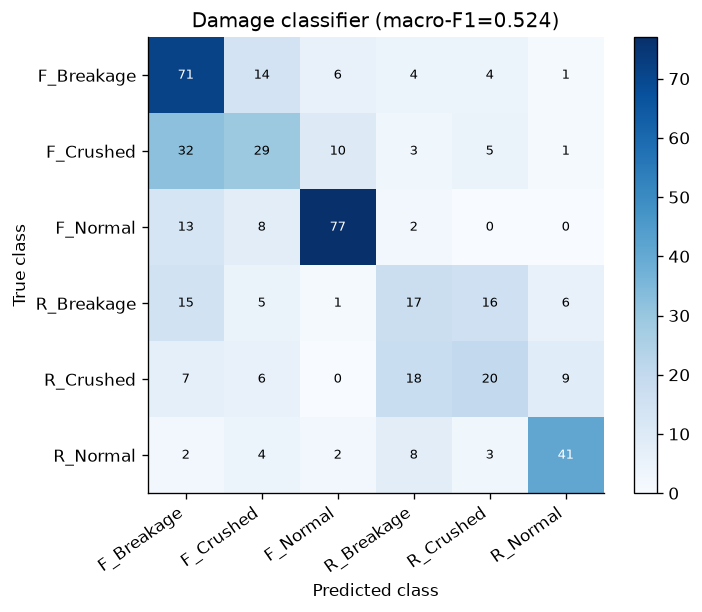

In [3]:
fig, ax = plt.subplots(figsize=(6.3, 5.2))
mat = cm.to_numpy()
img = ax.imshow(mat, cmap="Blues")
ax.set_xticks(range(len(cm.columns)), cm.columns, rotation=35, ha="right")
ax.set_yticks(range(len(cm.index)), cm.index)
ax.set_xlabel("Predicted class"); ax.set_ylabel("True class"); ax.set_title(f"Damage classifier (macro-F1={im['macro_f1']:.3f})")
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]): ax.text(j, i, int(mat[i,j]), ha="center", va="center", color="white" if mat[i,j] > mat.max()/2 else "black", fontsize=8)
fig.colorbar(img, ax=ax, fraction=.046); fig.tight_layout(); fig.savefig(FIGURES / "figure_07_image_confusion_matrix.png", bbox_inches="tight"); plt.show()

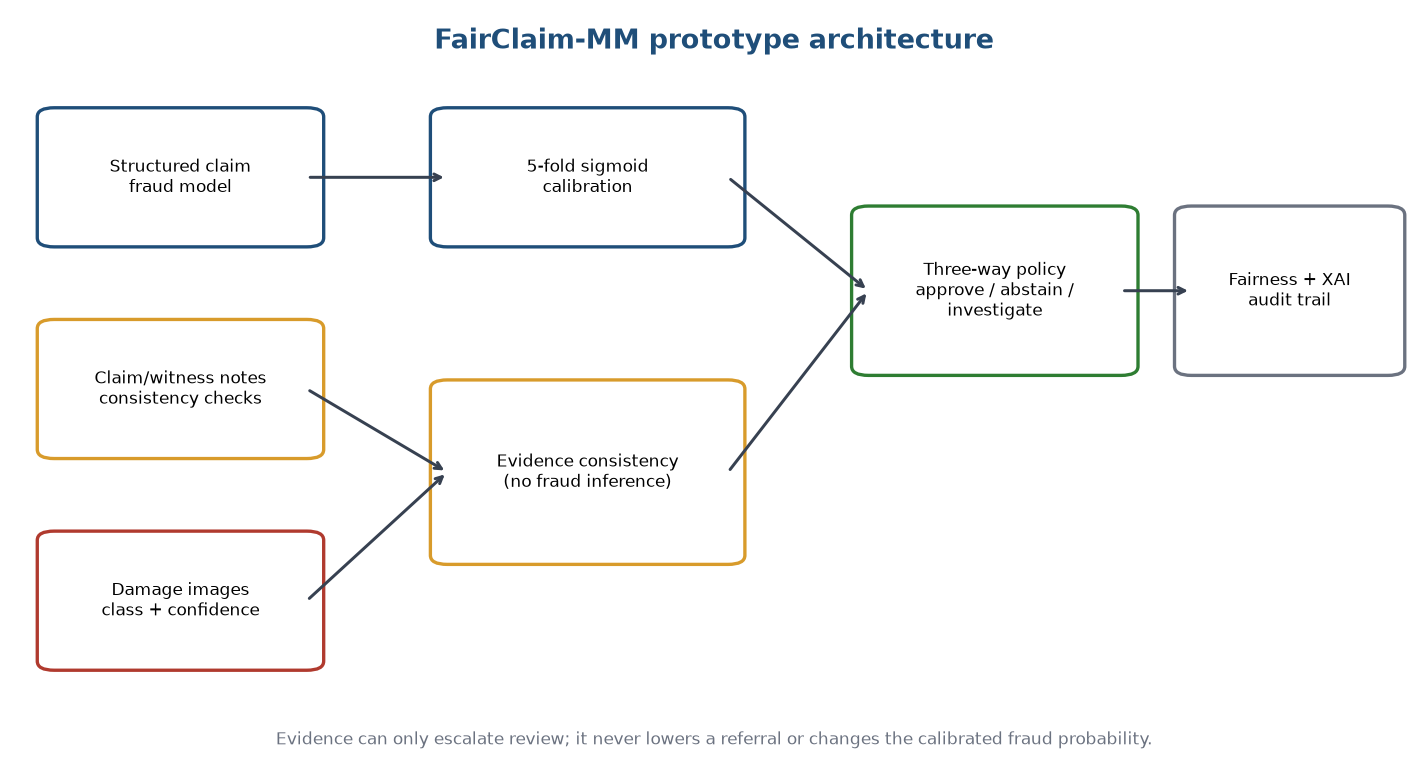

In [4]:
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(12, 6.6)); ax.axis("off")
boxes = {
 "claim": (0.03,.70,.18,.16,"Structured claim\nfraud model",BLUE),
 "text": (0.03,.42,.18,.16,"Claim/witness notes\nconsistency checks",GOLD),
 "image": (0.03,.14,.18,.16,"Damage images\nclass + confidence",RED),
 "cal": (.31,.70,.20,.16,"5-fold sigmoid\ncalibration",BLUE),
 "cons": (.31,.28,.20,.22,"Evidence consistency\n(no fraud inference)",GOLD),
 "policy": (.61,.53,.18,.20,"Three-way policy\napprove / abstain /\ninvestigate",GREEN),
 "audit": (.84,.53,.14,.20,"Fairness + XAI\naudit trail",GREY),
}
for key,(x,y,w,h,label,color) in boxes.items():
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle="round,pad=.012",facecolor="white",edgecolor=color,linewidth=2))
    ax.text(x+w/2,y+h/2,label,ha="center",va="center",fontsize=10)
def arrow(a,b):
    xa,ya,wa,ha,*_=boxes[a]; xb,yb,wb,hb,*_=boxes[b]
    ax.annotate("",xy=(xb,yb+hb/2),xytext=(xa+wa,ya+ha/2),arrowprops=dict(arrowstyle="->",lw=1.8,color="#374151"))
for a,b in [("claim","cal"),("text","cons"),("image","cons"),("cal","policy"),("cons","policy"),("policy","audit")]: arrow(a,b)
ax.text(.5,.96,"FairClaim-MM prototype architecture",ha="center",va="center",fontsize=16,fontweight="bold",color=BLUE)
ax.text(.5,.03,"Evidence can only escalate review; it never lowers a referral or changes the calibrated fraud probability.",ha="center",fontsize=10,color=GREY)
fig.tight_layout(); fig.savefig(FIGURES / "figure_08_architecture.png", bbox_inches="tight"); plt.show()

The image result (accuracy 0.554; macro-F1 0.524) is a feasibility baseline for six damage/view classes. At confidence ≥0.65, an image–note contradiction may escalate approve→abstain or abstain/investigate→investigate; it never reduces scrutiny and never changes the calibrated fraud score.